# Pipeline Unificado: Treinamento e Inferências Celulares Fujita --> Fujita faltante -->fujita pos imputação

Este notebook consolida o fluxo completo de modelagem, avaliação e diagnóstico comparativo em 3 seções integradas:

1. **[SEÇÃO 1: TREINAMENTO](#secao-1-treinamento)** - Treinamento da arquitetura MLP (600D $\to$ 128 $\to$ 64 $\to$ 32 $\to$ 7 classes) com dados de referência e exportação do modelo e scaler.
2. **[SEÇÃO 2: INFERÊNCIA - GENES FALTANTES](#secao-2-inferencia-genes-faltantes)** - Inferência sobre matriz com genes faltantes (valores sentinela), matriz de confusão, métricas detalhadas e sobreposição no espaço latente 32D (PCA & UMAP).
3. **[SEÇÃO 3: INFERÊNCIA - PÓS-IMPUTAÇÃO](#secao-3-inferencia-pos-imputacao)** - Inferência após a reconstrução e imputação dos genes ausentes pela rede neural Hopfield.


---
<a id='secao-1-treinamento'></a>
# ==============================================================================
# SEÇÃO 1: TREINAMENTO (Classificação Celular Fujita)
# ==============================================================================
> Etapa de carregamento de dados brutos de referência, escalonamento padrão, modelagem MLP, treinamento com validação estratificada e persistência dos artefatos (`clasificador_pan.keras` e `scaler_celular_pan.pkl`).


### Treinamento para classificação celular Fujita🏋️

In [22]:
import keras 
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

#### Importando dados

In [ ]:
from sqlalchemy import false
import polars as pl
y = pl.read_csv(r"C:\Users\Leticia\Documents\Letworkspace\Teste_MlP_fujita_para_fujitafaltante_fujitapos_imputacao\cell_types_numerico_fujita.txt",has_header=False)
X = pl.read_csv(r"C:\Users\Leticia\Downloads\matriz_projetada_adataF_binarizado_alinhado_1.txt", has_header=False, separator="\t",)

In [24]:
X.head(5)

column_1,column_2,column_3,column_4,column_5,column_6,column_7,column_8,column_9,column_10,column_11,column_12,column_13,column_14,column_15,column_16,column_17,column_18,column_19,column_20,column_21,column_22,column_23,column_24,column_25,column_26,column_27,column_28,column_29,column_30,column_31,column_32,column_33,column_34,column_35,column_36,column_37,…,column_564,column_565,column_566,column_567,column_568,column_569,column_570,column_571,column_572,column_573,column_574,column_575,column_576,column_577,column_578,column_579,column_580,column_581,column_582,column_583,column_584,column_585,column_586,column_587,column_588,column_589,column_590,column_591,column_592,column_593,column_594,column_595,column_596,column_597,column_598,column_599,column_600
str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,…,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""V1""","""V2""","""V3""","""V4""","""V5""","""V6""","""V7""","""V8""","""V9""","""V10""","""V11""","""V12""","""V13""","""V14""","""V15""","""V16""","""V17""","""V18""","""V19""","""V20""","""V21""","""V22""","""V23""","""V24""","""V25""","""V26""","""V27""","""V28""","""V29""","""V30""","""V31""","""V32""","""V33""","""V34""","""V35""","""V36""","""V37""",…,"""V564""","""V565""","""V566""","""V567""","""V568""","""V569""","""V570""","""V571""","""V572""","""V573""","""V574""","""V575""","""V576""","""V577""","""V578""","""V579""","""V580""","""V581""","""V582""","""V583""","""V584""","""V585""","""V586""","""V587""","""V588""","""V589""","""V590""","""V591""","""V592""","""V593""","""V594""","""V595""","""V596""","""V597""","""V598""","""V599""","""V600"""
"""0.267085927243014""","""-0.324275522860513""","""-0.450592159377612""","""-0.315825947734968""","""0.447657081312348""","""0.618090231165971""","""0.187401642750439""","""0.235185846924882""","""0.0249046440866593""","""0.367830668217663""","""-0.564324602623759""","""-0.849398158642778""","""-0.325689752695977""","""0.916186740389649""","""-0.381121572467617""","""-0.149995682396517""","""0.351222637102949""","""-0.456808631390791""","""0.626560538691941""","""-0.344807290080481""","""-0.223115897501683""","""-0.476940503656802""","""0.472949208844042""","""-0.329538475097141""","""-0.378987195674461""","""-0.097503534100186""","""1.22055260301569""","""0.368260834060001""","""0.352077708902541""","""0.487689439438356""","""0.0561244797484891""","""-0.219193379939912""","""-0.501893017878364""","""-0.117942398825941""","""-0.770616678459786""","""-1.30268982542064""","""0.780504649353691""",…,"""-0.3431211688264""","""0.862169664144106""","""-0.370500113472881""","""0.0448567119218238""","""-0.0345185393583084""","""-0.328023276005261""","""0.0897446455543582""","""0.146661038761918""","""0.497909618764623""","""-0.00667490241389631""","""-0.332066376135332""","""0.52876410111972""","""-0.155913013693038""","""-0.651917630981091""","""0.228473601843125""","""-0.789175490042508""","""-0.462679959282511""","""0.23008603382655""","""-0.232090112906551""","""0.637069283457266""","""-0.54212435714889""","""0.704333947564622""","""0.135300425092048""","""0.321501805730177""","""-0.0490590436176808""","""0.500639106702704""","""0.0849974041361681""","""0.158670292491179""","""0.226846663813788""","""0.378035640758574""","""-0.158904795986693""","""0.422548426205009""","""-0.557641604203454""","""0.500775266659712""","""0.192044306464286""","""-0.74877143318759""","""-0.62904039366679"""
"""0.311704649069643""","""-0.0517380275764565""","""-0.358630910927282""","""0.051871528295601""","""0.557735928981539""","""0.271870587382379""","""0.398697645623232""","""-0.133676410031665""","""0.397489407409249""","""0.307092383020032""","""-0.134266968829094""","""-0.588572472800145""","""-1.12136988886657""","""1.08033378957599""","""-0.

#### Filtrando conjunto de dados

In [25]:
# 1. Garante que y seja um array 1D numérico
if hasattr(y, "to_numpy"):
    y_arr = y.to_numpy().ravel()
else:
    y_arr = np.array(y).ravel()

# Garante que os dados sejam numéricos inteiros
y_arr = y_arr.astype(int)

# 2. Cria a máscara booleana 1D (classes 1 a 7)
mascara = (y_arr >= 1) & (y_arr <= 7)

# 3. Aplica a máscara para filtrar
if hasattr(X, "filter"):
    X_filtrado = X.filter(mascara)
    y_filtrado = y.filter(mascara)

# Subtrair 1 para as classes começarem em 0 (0 a 6):
y_filtrado = y_filtrado - 1


ShapeError: filter's length: 40912 differs from that of the series: 40914

#### Preparando conjunto de treino teste e validação

In [ ]:

X_treino_val, X_teste, y_treino_val, y_teste = train_test_split(X_filtrado, y_filtrado,  test_size = 0.20, random_state=42, stratify=y_filtrado)

##### 3. ESCALONAMENTO (Feature Scaling)

In [ ]:

# Calculamos média e desvio padrão APENAS com os dados de treino/validação
scaler = StandardScaler()
X_treino_val_normalizado = scaler.fit_transform(X_treino_val)
X_teste_normalizado = scaler.transform(X_teste)

In [ ]:
print("Classes presentes:", np.unique(y_filtrado))

Classes presentes: [0 1 2 3 4 5 6]


In [ ]:
valores, contagens = np.unique(y_filtrado, return_counts=True)
print(dict(zip(valores, contagens)))

{np.int64(0): np.int64(4366), np.int64(1): np.int64(188), np.int64(2): np.int64(9073), np.int64(3): np.int64(4567), np.int64(4): np.int64(1734), np.int64(5): np.int64(5762), np.int64(6): np.int64(1073)}


In [ ]:
# 4. CONSTRUÇÃO DA ARQUITETURA DO MLP
model = Sequential([
    # A primeira camada precisa saber o formato da entrada (600 features)
    Dense(128, activation='relu', input_shape=(600,)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    # A camada de saída dependerá do número de classes (ex: 1 para binário com sigmoid)
    Dense(7, activation='softmax') 
])

print("Modelo estruturado com sucesso!")

Modelo estruturado com sucesso!


c:\Users\Leticia\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:92: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


#### ⚙️ Compilação: Otimizador

In [ ]:
# Compilação do Modelo
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

#### 🏋️Treinamento do Modelo

In [ ]:

historico = model.fit(
    X_treino_val,
    y_treino_val,
    epochs=50,
    batch_size=64,
    validation_split=0.125
)

Epoch 1/50
293/293 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9703 - loss: 0.1073 - val_accuracy: 0.9966 - val_loss: 0.0138
Epoch 2/50
293/293 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9994 - loss: 0.0035 - val_accuracy: 0.9985 - val_loss: 0.0087
Epoch 3/50
293/293 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9987 - loss: 0.0040 - val_accuracy: 0.9996 - val_loss: 0.0028
Epoch 4/50
293/293 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9997 - loss: 0.0022 - val_accuracy: 0.9978 - val_loss: 0.0108
Epoch 5/50
293/293 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9999 - loss: 7.2092e-04 - val_accuracy: 0.9996 - val_loss: 0.0018
Epoch 6/50
293/293 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9995 - loss: 0.0030 - val_accuracy: 0.9996 - val_loss: 0.0038
Epoch 7/50
293/293 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9999 - loss: 4.3866e-04 - val_accuracy: 0.9996 - val_loss: 0.0034
Epoch 8/50
293/293 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 1.0000 - loss: 7.0132e-05 - val_

#### 📊 Avaliação final com teste e Matriz de Confusão.

In [ ]:
# Avaliação final no conjunto de teste
perda_teste, acuracia_teste = model.evaluate(X_teste_normalizado, y_teste)

print(f"Perda no Teste: {perda_teste:.4f}")
print(f"Acurácia no Teste: {acuracia_teste * 100:.2f}%")

168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9843 - loss: 0.0905
Perda no Teste: 0.0905
Acurácia no Teste: 98.43%


In [ ]:
# 1. Faz as predições de probabilidade (saída do softmax)
probabilidades = model.predict(X_teste_normalizado)

# 2. Pega o índice do neurônio com a maior probabilidade (np.argmax)
y_pred = np.argmax(probabilidades, axis=1)

168/168 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


c:\Users\Leticia\AppData\Local\Programs\Python\Python313\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128300 (\N{MICROSCOPE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


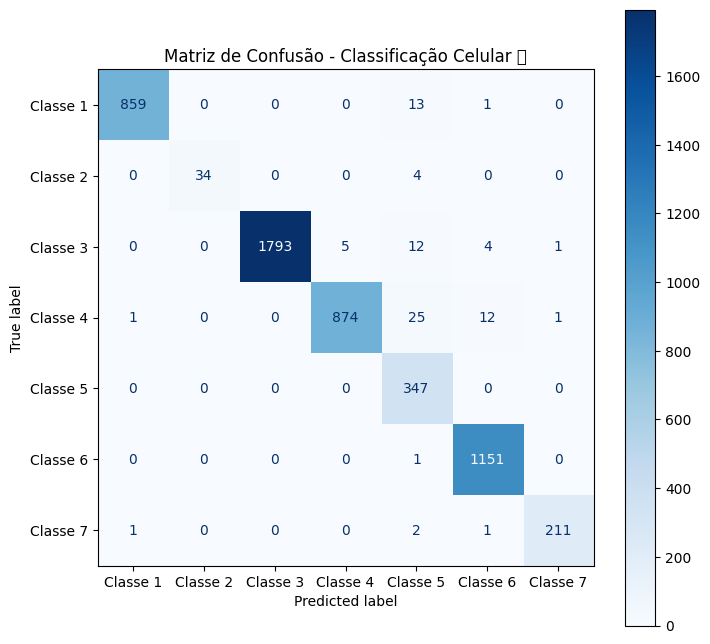

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Criando os rótulos originais para o gráfico (1 a 7)
rotulos_originais = [f"Classe {i}" for i in range(1, 8)]

# Plota a matriz usando as predições e os valores reais
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay.from_predictions(
    y_teste, 
    y_pred, 
    display_labels=rotulos_originais,
    cmap='Blues', # Paleta de cores (ex: Blues, Viridis)
    ax=ax
)

plt.title("Matriz de Confusão - Classificação Celular 🔬")
plt.show()

#### Salvar o modelo completo

In [ ]:

model.save('clasificador_pan.keras')

# 2. Em outro script/momento: carregar o modelo pronto para uso
import tensorflow as tf
modelo_carregado = tf.keras.models.load_model('clasificador_pan.keras')

In [ ]:
import joblib

# Salvar o scaler
joblib.dump(scaler, 'scaler_celular_pan.pkl')

# Para carregar futuramente
scaler_carregado = joblib.load('scaler_celular_pan.pkl')

---
<a id='secao-2-inferencia-genes-faltantes'></a>
# ==============================================================================
# SEÇÃO 2: INFERÊNCIA - GENES FALTANTES (Sentinela)
# ==============================================================================
> Inferência direta sobre os dados celulares alvo contendo genes ausentes preenchidos com valor sentinela, acompanhada de matriz de confusão, análise de métricas por classe e projeção latente (PCA & UMAP) para diagnóstico de Data Drift / Batch Effect.


#Inferencia Fujita Faltantes

837/837 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step
🎯 Acurácia Global da Inferência: 99.15%

📋 Relatório de Classificação por Classe:
              precision    recall  f1-score   support

    Classe 1       1.00      1.00      1.00      4366
    Classe 2       0.99      0.99      0.99       188
    Classe 3       0.98      1.00      0.99      9073
    Classe 4       0.99      0.99      0.99      4567
    Classe 5       1.00      0.99      1.00      1734
    Classe 6       1.00      0.98      0.99      5762
    Classe 7       0.99      1.00      0.99      1073

    accuracy                           0.99     26763
   macro avg       0.99      0.99      0.99     26763
weighted avg       0.99      0.99      0.99     26763



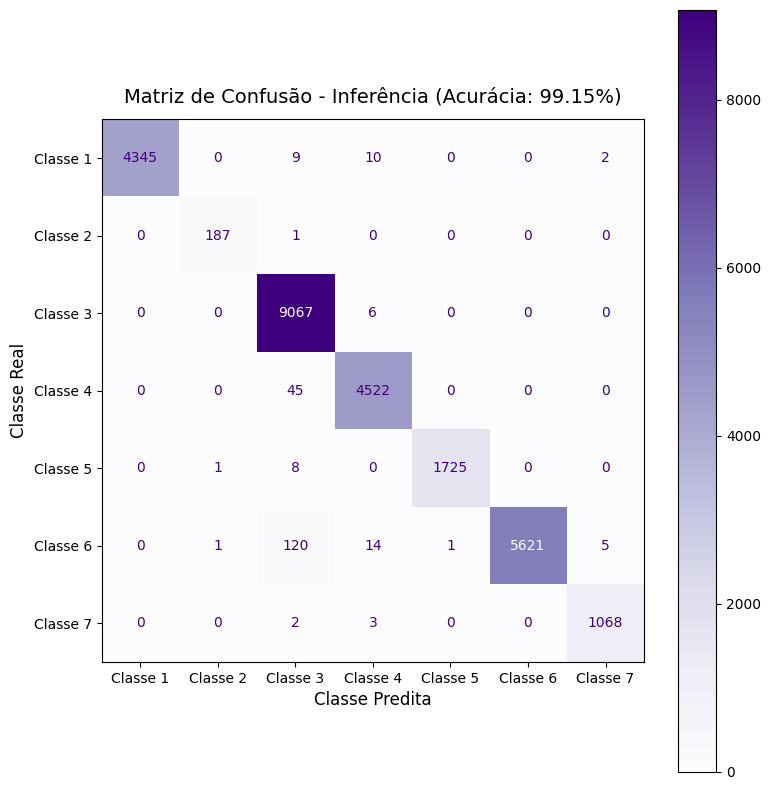

In [ ]:
import numpy as np
import tensorflow as tf
import joblib
import polars as pl 
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

# ==============================================================================
# 1. CARREGAMENTO DOS DADOS E RÓTULOS REAIS
# ==============================================================================
novos_dados_brutos = pl.read_csv(
    r"C:\Users\Leticia\Downloads\matriz_sweep600d_com_sentinela.txt",
    separator="\t",
    has_header=False,
)

y_rotulos = pl.read_csv(
    r'C:\Users\Leticia\Documents\Letworkspace\Treinamento-MLP-Mathys\Inputs\rotulos\cell_types_numerico_fujita.txt',
    has_header=False
)
y_arr = y_rotulos.to_numpy().ravel()

# ==============================================================================
# 2. FILTRANDO APENAS AS CLASSES 1 A 7 PARA AVALIAÇÃO
# ==============================================================================
mascara_1_7 = (y_arr >= 1) & (y_arr <= 7)

# Dados de entrada e rótulos reais correspondentes
X_inferencia = novos_dados_brutos.filter(mascara_1_7)
y_real = y_arr[mascara_1_7]

# ==============================================================================
# 3. NORMALIZAÇÃO E PREDIÇÃO
# ==============================================================================
modelo = tf.keras.models.load_model(r'C:\Users\Leticia\Documents\Letworkspace\Treinamento-MLP-Mathys\teste_pan_ausentes\clasificador_pan.keras')
scaler = joblib.load(r'C:\Users\Leticia\Documents\Letworkspace\Treinamento-MLP-Mathys\teste_pan_ausentes\scaler_celular_pan.pkl')

X_inferencia_norm = scaler.transform(X_inferencia)
probabilidades = modelo.predict(X_inferencia_norm)

# Convertendo índices (0 a 6) para classes reais (1 a 7)
y_pred = np.argmax(probabilidades, axis=1) + 1

# ==============================================================================
# 4. ACURÁCIA GLOBAL E RELATÓRIO DE CLASSIFICAÇÃO
# ==============================================================================
acuracia_global = accuracy_score(y_real, y_pred)
print(f"🎯 Acurácia Global da Inferência: {acuracia_global * 100:.2f}%\n")

print("📋 Relatório de Classificação por Classe:")
rotulos_classes = [f"Classe {i}" for i in range(1, 8)]
print(classification_report(y_real, y_pred, target_names=rotulos_classes))

# ==============================================================================
# 5. PLOT DA MATRIZ DE CONFUSÃO
# ==============================================================================
fig, ax = plt.subplots(figsize=(8, 8))

ConfusionMatrixDisplay.from_predictions(
    y_real,
    y_pred,
    display_labels=rotulos_classes,
    cmap='Purples',
    ax=ax,
    values_format='d'  # Exibe os números inteiros
)

plt.title(f"Matriz de Confusão - Inferência (Acurácia: {acuracia_global * 100:.2f}%)", fontsize=14, pad=12)
plt.xlabel("Classe Predita", fontsize=12)
plt.ylabel("Classe Real", fontsize=12)
plt.grid(False)
plt.tight_layout()
plt.show()


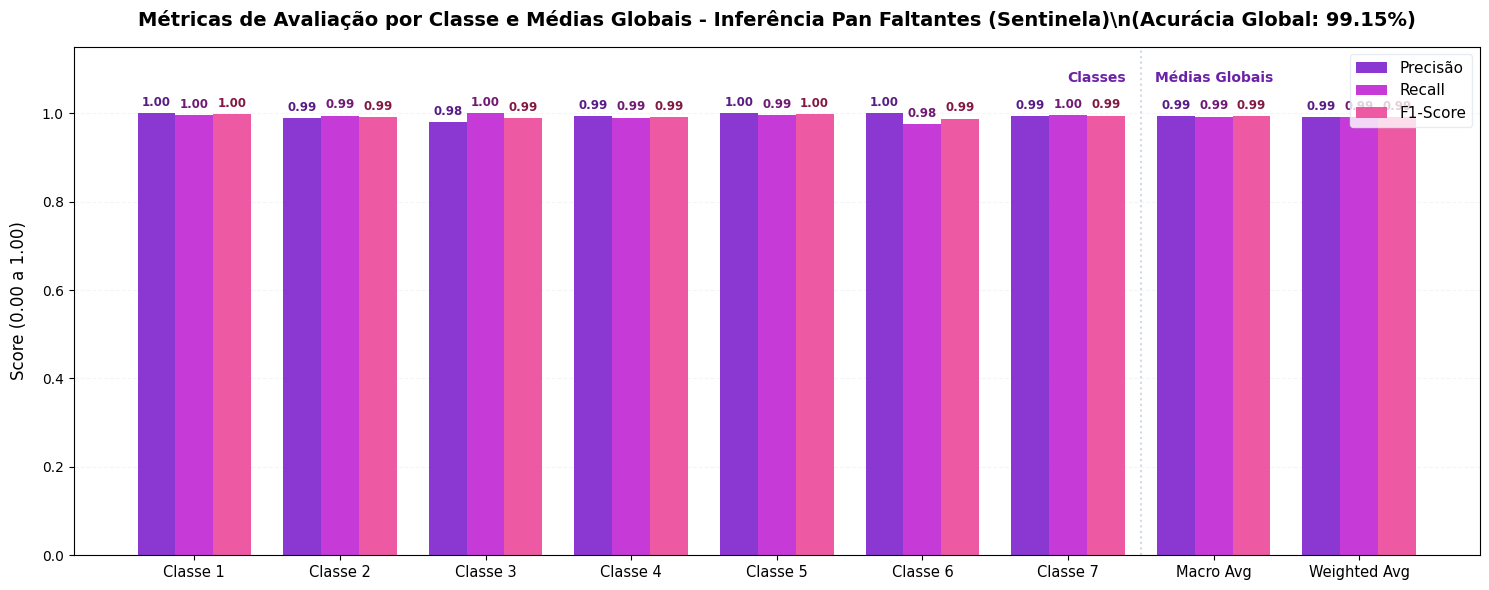

In [ ]:
# ==============================================================================
# 6. PLOT DAS MÉTRICAS DE AVALIAÇÃO POR CLASSE E MÉDIAS GLOBAIS (BARRAS AGRUPADAS)
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

# 1. Extração estruturada do relatório de classificação
relatorio = classification_report(
    y_real,
    y_pred,
    labels=list(range(1, 8)),
    target_names=rotulos_classes,
    output_dict=True,
    zero_division=0
)

# 2. Grupos de classes individuais + médias globais (Macro e Weighted Avg)
grupos = rotulos_classes + ['Macro Avg', 'Weighted Avg']
chaves = rotulos_classes + ['macro avg', 'weighted avg']

precisions = [relatorio[c]['precision'] for c in chaves]
recalls    = [relatorio[c]['recall'] for c in chaves]
f1_scores  = [relatorio[c]['f1-score'] for c in chaves]

# 3. Configuração dos eixos e geometria das barras
x = np.arange(len(grupos))
width = 0.26  # Largura de cada barra

fig, ax = plt.subplots(figsize=(15, 6), dpi=100)

# 4. Criação das barras agrupadas em tons de roxo e rosa
color_prec = '#7e22ce'   # Roxo profundo (Purple)
color_rec  = '#c026d3'   # Fúcsia / Magenta
color_f1   = '#ec4899'   # Rosa vibrante (Pink)

rects1 = ax.bar(x - width, precisions, width, label='Precisão', color=color_prec, edgecolor='none', alpha=0.9)
rects2 = ax.bar(x,         recalls,    width, label='Recall',   color=color_rec,  edgecolor='none', alpha=0.9)
rects3 = ax.bar(x + width, f1_scores,  width, label='F1-Score', color=color_f1,   edgecolor='none', alpha=0.9)

# 5. Adição de valores no topo das barras com tipografia contrastante
ax.bar_label(rects1, fmt='%.2f', padding=3, fontsize=8.5, fontweight='bold', color='#581c87')
ax.bar_label(rects2, fmt='%.2f', padding=3, fontsize=8.5, fontweight='bold', color='#701a75')
ax.bar_label(rects3, fmt='%.2f', padding=3, fontsize=8.5, fontweight='bold', color='#831843')

# Linha divisória discreta entre classes e médias globais
ax.axvline(x=6.5, color='#cbd5e1', linestyle=':', linewidth=1.5, alpha=0.9)
ax.text(6.4, 1.08, 'Classes', ha='right', va='center', fontsize=10, fontweight='bold', color='#6b21a8')
ax.text(6.6, 1.08, 'Médias Globais', ha='left', va='center', fontsize=10, fontweight='bold', color='#6b21a8')

# 6. Customização estética dos eixos
ax.set_ylabel('Score (0.00 a 1.00)', fontsize=12, labelpad=10)
ax.set_title(
    f'Métricas de Avaliação por Classe e Médias Globais - Inferência Pan Faltantes (Sentinela)\\n(Acurácia Global: {acuracia_global * 100:.2f}%)',
    fontsize=14,
    fontweight='bold',
    pad=15
)
ax.set_xticks(x)
ax.set_xticklabels(grupos, fontsize=10.5, fontweight='medium')
ax.set_ylim(0, 1.15)  # Espaço para os rótulos numéricos no topo

# Linha de grade horizontal sutil
ax.grid(axis='y', linestyle='--', alpha=0.4, color='#e2e8f0')
ax.set_axisbelow(True)

# Legenda destacada
ax.legend(loc='upper right', frameon=True, facecolor='#ffffff', edgecolor='#e2e8f0', fontsize=11)

# Ajuste fino e exibição
plt.tight_layout()
plt.show()


### 7. Sobreposição no Espaço Latente (Treino vs. Inferência via UMAP/PCA)
Projeta os embeddings da penúltima camada (32D) dos novos dados sobrepostos aos dados de treino de referência.
- **Treino:** Pontos coloridos por tipo celular (Classes 1 a 7).
- **Inferência:** Estrelas pretas (★) sobrepostas para detecção imediata de *Data Drift* ou *Batch Effect*.

📐 Extrator latente estruturado com sucesso! Dimensão de saída: (None, 32)
⏳ Carregando conjunto de dados de treino de referência...
🧠 Extraindo embeddings latentes (32D)...
✅ Treino: 57457 células | Inferência: 26763 células
📊 Ajustando PCA (fit no treino, transform na inferência)...
🗺️ Ajustando UMAP (fit no treino, transform na inferência)...


Exception ignored on calling ctypes callback function <function ExecutionEngine._raw_object_cache_notify at 0x000002818F72A020>:
Traceback (most recent call last):
  File "c:\Users\Leticia\AppData\Local\Programs\Python\Python313\Lib\site-packages\llvmlite\binding\executionengine.py", line 178, in _raw_object_cache_notify
    def _raw_object_cache_notify(self, data):
KeyboardInterrupt: 


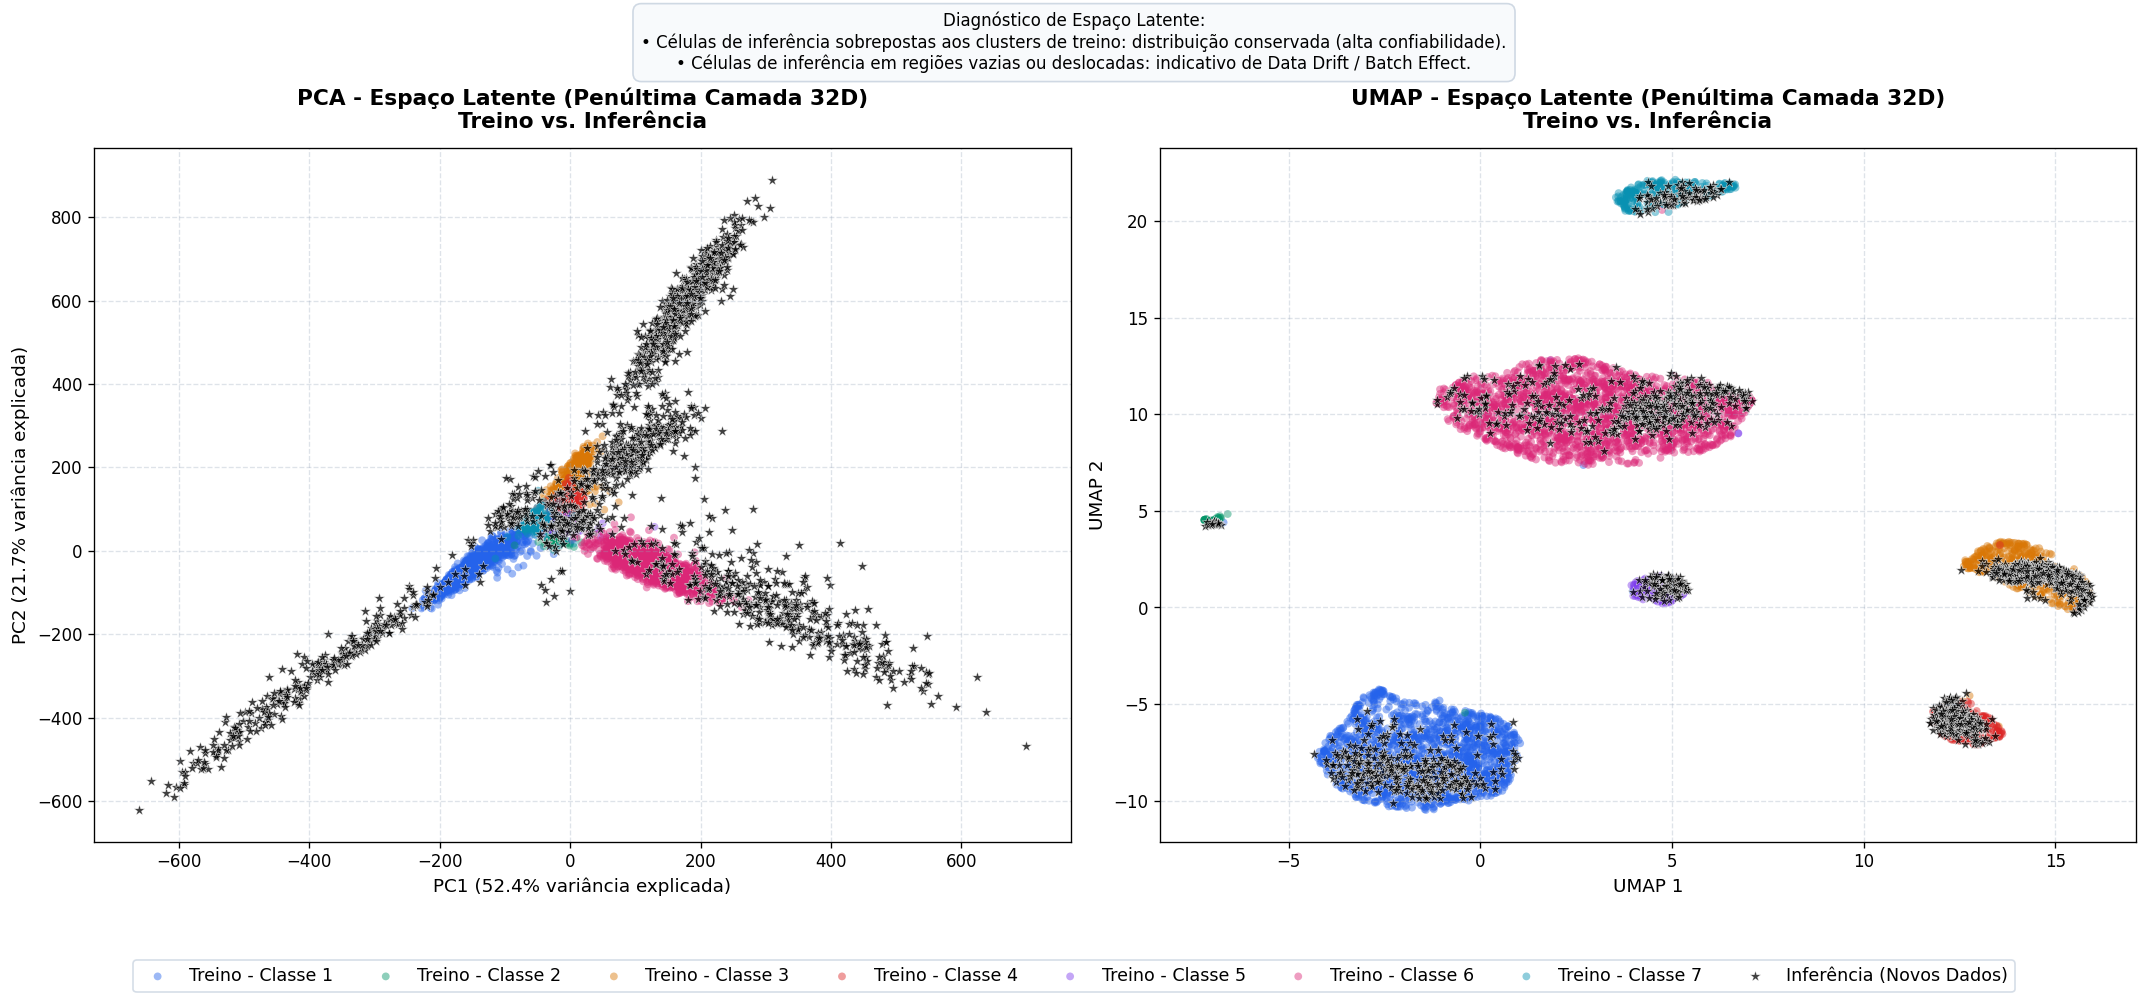

In [ ]:
# ==============================================================================
# 7. PROJEÇÃO E SOBREPOSIÇÃO NO ESPAÇO LATENTE (TREINO VS. INFERÊNCIA VIA PCA & UMAP)
# ==============================================================================
import warnings
warnings.filterwarnings('ignore')

from sklearn.decomposition import PCA
import umap
import matplotlib.pyplot as plt
import polars as pl
import numpy as np
import tensorflow as tf

# 1. Definição do extrator de embeddings da penúltima camada (dense_2, dimensão 32)
extrator_latente = tf.keras.Model(
    inputs=modelo.inputs,
    outputs=modelo.layers[-2].output
)
print("📐 Extrator latente estruturado com sucesso! Dimensão de saída:", extrator_latente.output_shape)

# 2. Carregamento dos dados de referência de treino
print("⏳ Carregando conjunto de dados de treino de referência...")
y_treino_raw = pl.read_csv(
    r"C:\Users\Leticia\Documents\Letworkspace\Treinamento-MLP-Mathys\Inputs\rotulos\PanNumerico.csv",
    has_header=False
)
X_treino_raw = pl.read_csv(
    r"C:\Users\Leticia\Downloads\matriz_reduzida_sweepREF.txt",
    has_header=False,
    separator="\t"
)

# Filtragem das classes 1 a 7 do treino (consistente com a inferência)
y_treino_arr = y_treino_raw.to_numpy().ravel()
mascara_treino = (y_treino_arr >= 1) & (y_treino_arr <= 7)
X_treino_filt = X_treino_raw.filter(mascara_treino)
y_treino_filt = y_treino_arr[mascara_treino]

# Normalização usando o MESMO scaler do treino
X_treino_norm = scaler.transform(X_treino_filt)

# 3. Extração dos embeddings da penúltima camada
print("🧠 Extraindo embeddings latentes (32D)...")
embeddings_treino = extrator_latente.predict(X_treino_norm, batch_size=512, verbose=0)
embeddings_inferencia = extrator_latente.predict(X_inferencia_norm, batch_size=512, verbose=0)
print(f"✅ Treino: {embeddings_treino.shape[0]} células | Inferência: {embeddings_inferencia.shape[0]} células")

# 4. Amostragem representativa (evita overplotting e otimiza a responsividade do UMAP)
N_AMOSTRA_TREINO = 5000       # Ajustável (ou None para usar 100% dos dados)
N_AMOSTRA_INFERENCIA = 2000   # Ajustável (ou None para usar 100% dos dados)
rng = np.random.default_rng(42)

if N_AMOSTRA_TREINO is not None and len(embeddings_treino) > N_AMOSTRA_TREINO:
    idx_treino = rng.choice(len(embeddings_treino), size=N_AMOSTRA_TREINO, replace=False)
else:
    idx_treino = np.arange(len(embeddings_treino))

if N_AMOSTRA_INFERENCIA is not None and len(embeddings_inferencia) > N_AMOSTRA_INFERENCIA:
    idx_inf = rng.choice(len(embeddings_inferencia), size=N_AMOSTRA_INFERENCIA, replace=False)
else:
    idx_inf = np.arange(len(embeddings_inferencia))

emb_treino_sub = embeddings_treino[idx_treino]
y_treino_sub = y_treino_filt[idx_treino]

emb_inf_sub = embeddings_inferencia[idx_inf]
y_inf_sub = y_real[idx_inf]

# 5. Redução de Dimensionalidade (PCA e UMAP calibrados no Treino)
print("📊 Ajustando PCA (fit no treino, transform na inferência)...")
pca = PCA(n_components=2, random_state=42)
pca_treino = pca.fit_transform(emb_treino_sub)
pca_inf = pca.transform(emb_inf_sub)
var_exp = pca.explained_variance_ratio_ * 100

print("🗺️ Ajustando UMAP (fit no treino, transform na inferência)...")
reducer = umap.UMAP(n_neighbors=30, min_dist=0.3, metric='cosine', random_state=42)
umap_treino = reducer.fit_transform(emb_treino_sub)
umap_inf = reducer.transform(emb_inf_sub)

# 6. Configuração e Plot da Sobreposição no Espaço Latente (Painel Lado a Lado)
paleta_classes = [
    '#2563eb',  # Classe 1: Azul vibrante
    '#059669',  # Classe 2: Esmeralda
    '#d97706',  # Classe 3: Âmbar
    '#dc2626',  # Classe 4: Carmesim
    '#7c3aed',  # Classe 5: Violeta
    '#db2777',  # Classe 6: Rosa escuro
    '#0891b2'   # Classe 7: Ciano
]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8), dpi=120)

# --- Subplot 1: PCA ---
for i in range(1, 8):
    mask_c = (y_treino_sub == i)
    if np.any(mask_c):
        ax1.scatter(
            pca_treino[mask_c, 0],
            pca_treino[mask_c, 1],
            c=paleta_classes[i - 1],
            label=f'Treino - Classe {i}',
            alpha=0.45,
            s=22,
            edgecolor='none'
        )

# Sobreposição dos dados novos de inferência (estrelas pretas)
ax1.scatter(
    pca_inf[:, 0],
    pca_inf[:, 1],
    c='black',
    marker='*',
    s=45,
    alpha=0.75,
    edgecolor='white',
    linewidth=0.3,
    label='Inferência (Novos Dados)'
)

ax1.set_title(
    f"PCA - Espaço Latente (Penúltima Camada 32D)\nTreino vs. Inferência",
    fontsize=13,
    fontweight='bold',
    pad=12
)
ax1.set_xlabel(f"PC1 ({var_exp[0]:.1f}% variância explicada)", fontsize=11)
ax1.set_ylabel(f"PC2 ({var_exp[1]:.1f}% variância explicada)", fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.3, color='#94a3b8')

# --- Subplot 2: UMAP ---
for i in range(1, 8):
    mask_c = (y_treino_sub == i)
    if np.any(mask_c):
        ax2.scatter(
            umap_treino[mask_c, 0],
            umap_treino[mask_c, 1],
            c=paleta_classes[i - 1],
            label=f'Treino - Classe {i}',
            alpha=0.45,
            s=22,
            edgecolor='none'
        )

# Sobreposição dos dados novos de inferência (estrelas pretas)
ax2.scatter(
    umap_inf[:, 0],
    umap_inf[:, 1],
    c='black',
    marker='*',
    s=45,
    alpha=0.75,
    edgecolor='white',
    linewidth=0.3,
    label='Inferência (Novos Dados)'
)

ax2.set_title(
    "UMAP - Espaço Latente (Penúltima Camada 32D)\nTreino vs. Inferência",
    fontsize=13,
    fontweight='bold',
    pad=12
)
ax2.set_xlabel("UMAP 1", fontsize=11)
ax2.set_ylabel("UMAP 2", fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.3, color='#94a3b8')

# Legenda compartilhada refinada
handles, labels = ax2.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='lower center',
    bbox_to_anchor=(0.5, -0.05),
    ncol=8,
    frameon=True,
    facecolor='#ffffff',
    edgecolor='#cbd5e1',
    fontsize=10.5
)

# Caixa de interpretação diagnóstica
interpretacao = (
    "Diagnóstico de Espaço Latente:\n"
    "• Células de inferência sobrepostas aos clusters de treino: distribuição conservada (alta confiabilidade).\n"
    "• Células de inferência em regiões vazias ou deslocadas: indicativo de Data Drift / Batch Effect."
)
fig.text(
    0.5, 0.98, interpretacao,
    ha='center', va='top', fontsize=10,
    bbox=dict(boxstyle='round,pad=0.5', facecolor='#f8fafc', edgecolor='#cbd5e1', alpha=0.9)
)

plt.tight_layout(rect=[0, 0.04, 1, 0.92])
plt.show()


---
<a id='secao-3-inferencia-pos-imputacao'></a>
# ==============================================================================
# SEÇÃO 3: INFERÊNCIA - PÓS-IMPUTAÇÃO (Rede Hopfield)
# ==============================================================================
> Inferência sobre a matriz celular após o processo de imputação e reconstrução de genes pela rede Hopfield, avaliando o ganho de acurácia global e a recuperação das métricas em cada classe celular.


# Inferência Pan Pós-Imputação


In [ ]:
import numpy as np
import tensorflow as tf
import joblib
import polars as pl 
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

# ==============================================================================
# 1. CARREGAMENTO DOS DADOS E RÓTULOS REAIS
# ==============================================================================
novos_dados_brutos = pl.read_csv(
    r"C:\Users\Leticia\Downloads\sweep_alvo_pos_imputacao (1).txt",
    separator="\t",
    has_header=False,
)

y_rotulos = pl.read_csv(
   r"C:\Users\Leticia\Documents\Letworkspace\Treinamento-MLP-Mathys\Inputs\rotulos\tipos_celulares_numericoMs.txt",
    has_header=False
)
y_arr = y_rotulos.to_numpy().ravel()

# ==============================================================================
# 2. FILTRANDO APENAS AS CLASSES 1 A 7 PARA AVALIAÇÃO
# ==============================================================================
mascara_1_7 = (y_arr >= 1) & (y_arr <= 7)

# Dados de entrada e rótulos reais correspondentes
X_inferencia = novos_dados_brutos.filter(mascara_1_7)
y_real = y_arr[mascara_1_7]

# ==============================================================================
# 3. NORMALIZAÇÃO E PREDIÇÃO
# ==============================================================================
modelo = tf.keras.models.load_model(r'C:\Users\Leticia\Documents\Letworkspace\Treinamento-MLP-Mathys\teste_pan_ausentes\clasificador_pan.keras')
scaler = joblib.load(r'C:\Users\Leticia\Documents\Letworkspace\Treinamento-MLP-Mathys\teste_pan_ausentes\scaler_celular_pan.pkl')

X_inferencia_norm = scaler.transform(X_inferencia)
probabilidades = modelo.predict(X_inferencia_norm)

# Convertendo índices (0 a 6) para classes reais (1 a 7)
y_pred = np.argmax(probabilidades, axis=1) + 1

# ==============================================================================
# 4. ACURÁCIA GLOBAL E RELATÓRIO DE CLASSIFICAÇÃO
# ==============================================================================
acuracia_global = accuracy_score(y_real, y_pred)
print(f"🎯 Acurácia Global da Inferência: {acuracia_global * 100:.2f}%\n")

print("📋 Relatório de Classificação por Classe:")
rotulos_classes = [f"Classe {i}" for i in range(1, 8)]
print(classification_report(y_real, y_pred, target_names=rotulos_classes))

# ==============================================================================
# 5. PLOT DA MATRIZ DE CONFUSÃO
# ==============================================================================
fig, ax = plt.subplots(figsize=(8, 8))

ConfusionMatrixDisplay.from_predictions(
    y_real,
    y_pred,
    display_labels=rotulos_classes,
    cmap='Purples',
    ax=ax,
    values_format='d'  # Exibe os números inteiros
)

plt.title(f"Matriz de Confusão -\n Após a imputação de 30 mil genes pela rede Hopfield \n(Acurácia: {acuracia_global * 100:.2f}%)", fontsize=14, pad=12)
plt.xlabel("Classe Predita", fontsize=12)
plt.ylabel("Classe Real", fontsize=12)
plt.grid(False)
plt.tight_layout()
plt.show()


FileNotFoundError: O sistema não pode encontrar o arquivo especificado. (os error 2): C:\Users\Leticia\Downloads\sweep_alvo_pos_imputacao (1).txt

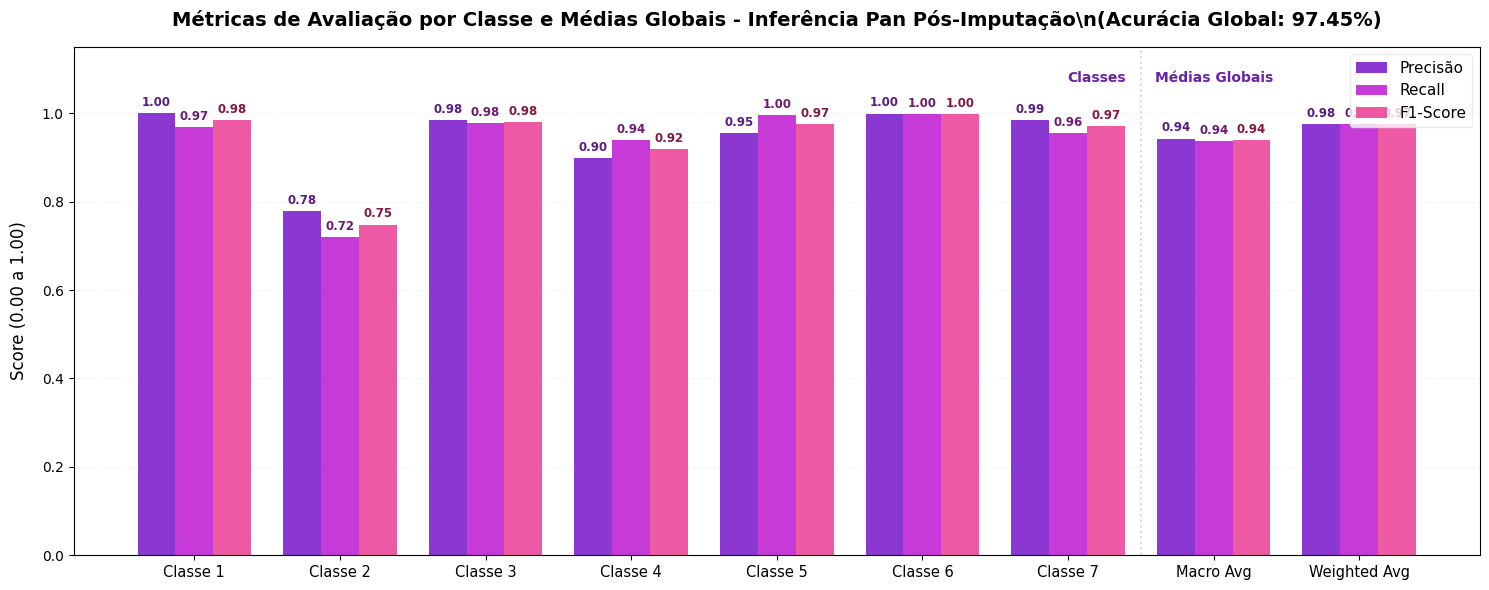

In [ ]:
# ==============================================================================
# 6. PLOT DAS MÉTRICAS DE AVALIAÇÃO POR CLASSE E MÉDIAS GLOBAIS (BARRAS AGRUPADAS)
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

# 1. Extração estruturada do relatório de classificação
relatorio = classification_report(
    y_real,
    y_pred,
    labels=list(range(1, 8)),
    target_names=rotulos_classes,
    output_dict=True,
    zero_division=0
)

# 2. Grupos de classes individuais + médias globais (Macro e Weighted Avg)
grupos = rotulos_classes + ['Macro Avg', 'Weighted Avg']
chaves = rotulos_classes + ['macro avg', 'weighted avg']

precisions = [relatorio[c]['precision'] for c in chaves]
recalls    = [relatorio[c]['recall'] for c in chaves]
f1_scores  = [relatorio[c]['f1-score'] for c in chaves]

# 3. Configuração dos eixos e geometria das barras
x = np.arange(len(grupos))
width = 0.26  # Largura de cada barra

fig, ax = plt.subplots(figsize=(15, 6), dpi=100)

# 4. Criação das barras agrupadas em tons de roxo e rosa
color_prec = '#7e22ce'   # Roxo profundo (Purple)
color_rec  = '#c026d3'   # Fúcsia / Magenta
color_f1   = '#ec4899'   # Rosa vibrante (Pink)

rects1 = ax.bar(x - width, precisions, width, label='Precisão', color=color_prec, edgecolor='none', alpha=0.9)
rects2 = ax.bar(x,         recalls,    width, label='Recall',   color=color_rec,  edgecolor='none', alpha=0.9)
rects3 = ax.bar(x + width, f1_scores,  width, label='F1-Score', color=color_f1,   edgecolor='none', alpha=0.9)

# 5. Adição de valores no topo das barras com tipografia contrastante
ax.bar_label(rects1, fmt='%.2f', padding=3, fontsize=8.5, fontweight='bold', color='#581c87')
ax.bar_label(rects2, fmt='%.2f', padding=3, fontsize=8.5, fontweight='bold', color='#701a75')
ax.bar_label(rects3, fmt='%.2f', padding=3, fontsize=8.5, fontweight='bold', color='#831843')

# Linha divisória discreta entre classes e médias globais
ax.axvline(x=6.5, color='#cbd5e1', linestyle=':', linewidth=1.5, alpha=0.9)
ax.text(6.4, 1.08, 'Classes', ha='right', va='center', fontsize=10, fontweight='bold', color='#6b21a8')
ax.text(6.6, 1.08, 'Médias Globais', ha='left', va='center', fontsize=10, fontweight='bold', color='#6b21a8')

# 6. Customização estética dos eixos
ax.set_ylabel('Score (0.00 a 1.00)', fontsize=12, labelpad=10)
ax.set_title(
    f'Métricas de Avaliação por Classe e Médias Globais - Inferência Pan Pós-Imputação\\n(Acurácia Global: {acuracia_global * 100:.2f}%)',
    fontsize=14,
    fontweight='bold',
    pad=15
)
ax.set_xticks(x)
ax.set_xticklabels(grupos, fontsize=10.5, fontweight='medium')
ax.set_ylim(0, 1.15)  # Espaço para os rótulos numéricos no topo

# Linha de grade horizontal sutil
ax.grid(axis='y', linestyle='--', alpha=0.4, color='#e2e8f0')
ax.set_axisbelow(True)

# Legenda destacada
ax.legend(loc='upper right', frameon=True, facecolor='#ffffff', edgecolor='#e2e8f0', fontsize=11)

# Ajuste fino e exibição
plt.tight_layout()
plt.show()
